In [2]:

# Step 1: Install the libraries for our ML project

!pip -q install transformers datasets accelerate scikit-learn matplotlib pandas


In [3]:

# Step 2: Check whether our training environment is ready

import torch
import pandas as pd
import sklearn
import transformers

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU available right now. We can still continue setup.")


PyTorch: 2.11.0+cu130
Transformers: 5.21.0
GPU available: True
GPU name: Tesla T4


In [8]:

!pip -q install datasets

from datasets import load_dataset

dataset = load_dataset("batuhanmtl/job_resume_fit")

print(dataset)
print("\nAvailable splits:")
print(dataset.keys())

first_split = list(dataset.keys())[0]
print("\nColumn names:")
print(dataset[first_split].column_names)


DatasetDict({
    train: Dataset({
        features: ['ID', 'resume_text', 'job_text', 'category', 'job_required_skills', 'resume_skill_list', 'ai_matched_skills', 'ai_match_score', 'skill_string_match_score', 'fuzzy_match_score'],
        num_rows: 2385
    })
})

Available splits:
dict_keys(['train'])

Column names:
['ID', 'resume_text', 'job_text', 'category', 'job_required_skills', 'resume_skill_list', 'ai_matched_skills', 'ai_match_score', 'skill_string_match_score', 'fuzzy_match_score']


In [5]:

# STEP 4: Inspect dataset quality and matching scores

import pandas as pd

df = dataset["train"].to_pandas()

# Check the dataset structure without printing personal resume details
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df[[
    "resume_text",
    "job_text",
    "ai_match_score",
    "skill_string_match_score",
    "fuzzy_match_score"
]].isnull().sum())

print("\nMatching score statistics:")
display(
    df[[
        "ai_match_score",
        "skill_string_match_score",
        "fuzzy_match_score"
    ]].describe().round(2)
)

# Proposed three-class labels
df["label"] = pd.cut(
    df["ai_match_score"],
    bins=[-0.01, 40, 70, 100],
    labels=["Weak", "Moderate", "Strong"],
    right=False
)

print("\nLabel distribution:")
display(df["label"].value_counts().sort_index())

print("\nLabel proportions (%):")
display(
    (df["label"].value_counts(normalize=True) * 100)
    .round(1)
    .sort_index()
)

print("\nDuplicate resume-job pairs:",
      df.duplicated(subset=["resume_text", "job_text"]).sum())

print("\nSample scores and labels:")
display(
    df[[
        "category",
        "ai_match_score",
        "label",
        "skill_string_match_score",
        "fuzzy_match_score"
    ]].head(10)
)


Dataset shape: (2385, 10)

Missing values:
resume_text                 0
job_text                    0
ai_match_score              0
skill_string_match_score    0
fuzzy_match_score           0
dtype: int64

Matching score statistics:


,ai_match_score,skill_string_match_score,fuzzy_match_score
count,2385.00,2385.00,2385.00
mean,44.04,11.55,56.58
std,24.63,7.49,6.78
min,0.00,0.00,26.15
25%,22.23,6.06,52.03
50%,40.65,10.00,56.40
75%,63.95,15.79,61.07
max,100.00,41.67,84.41



Label distribution:


,count
label,
Weak,1175
Moderate,745
Strong,458



Label proportions (%):


,proportion
label,
Weak,49.4
Moderate,31.3
Strong,19.3



Duplicate resume-job pairs: 2

Sample scores and labels:


,category,ai_match_score,label,skill_string_match_score,fuzzy_match_score
0,HR,49.40,Moderate,12.50,63.24
1,HR,77.64,Strong,16.67,59.07
2,HR,100.00,NaN,20.83,61.89
3,HR,32.63,Weak,8.33,52.95
4,HR,86.03,Strong,29.17,64.36
5,HR,73.15,Strong,16.67,58.22
6,HR,71.36,Strong,29.17,64.29
7,HR,86.03,Strong,8.33,56.12
8,HR,95.81,Strong,25.00,65.34
9,HR,90.92,Strong,33.33,64.88


In [6]:

# STEP 5: Clean data, select 1,000 examples, and create reproducible splits

import pandas as pd
from sklearn.model_selection import train_test_split

# Start with the original training dataset
df = dataset["train"].to_pandas()

# Remove duplicate resume-job pairs
df = df.drop_duplicates(
    subset=["resume_text", "job_text"]
).copy()

# Remove rows missing required information
df = df.dropna(
    subset=["resume_text", "job_text", "ai_match_score"]
).copy()

# Keep valid matching scores
df = df[df["ai_match_score"].between(0, 100)].copy()

# Create the three classification labels
df["label"] = pd.cut(
    df["ai_match_score"],
    bins=[-0.01, 40, 70, 100.01],
    labels=["Weak", "Moderate", "Strong"],
    right=False
)

df = df.dropna(subset=["label"]).copy()

# Select exactly 1,000 examples while preserving class proportions
df, _ = train_test_split(
    df,
    train_size=1000,
    random_state=42,
    stratify=df["label"]
)

# Reset row numbering
df = df.reset_index(drop=True)

# Split into 70% training, 15% validation, 15% testing
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

# Save the selected dataset and splits
df.to_csv("resume_job_dataset_clean.csv", index=False)
train_df.to_csv("train.csv", index=False)
val_df.to_csv("validation.csv", index=False)
test_df.to_csv("test.csv", index=False)

# Display dataset information without exposing resume text
print("Total selected examples:", len(df))
print("Training examples:", len(train_df))
print("Validation examples:", len(val_df))
print("Test examples:", len(test_df))

print("\nOverall class distribution:")
print(df["label"].value_counts().sort_index())

print("\nTraining class distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_df["label"].value_counts().sort_index())

print("\nTest class distribution:")
print(test_df["label"].value_counts().sort_index())

print("\nDataset selection completed.")


Total selected examples: 1000
Training examples: 700
Validation examples: 150
Test examples: 150

Overall class distribution:
label
Weak        493
Moderate    312
Strong      195
Name: count, dtype: int64

Training class distribution:
label
Weak        345
Moderate    218
Strong      137
Name: count, dtype: int64

Validation class distribution:
label
Weak        74
Moderate    47
Strong      29
Name: count, dtype: int64

Test class distribution:
label
Weak        74
Moderate    47
Strong      29
Name: count, dtype: int64

Dataset selection completed.


BASELINE TEST RESULTS
Accuracy: 0.7133

Classification report:
              precision    recall  f1-score   support

        Weak       0.84      0.84      0.84        74
    Moderate       0.68      0.45      0.54        47
      Strong       0.53      0.83      0.65        29

    accuracy                           0.71       150
   macro avg       0.68      0.70      0.67       150
weighted avg       0.73      0.71      0.71       150



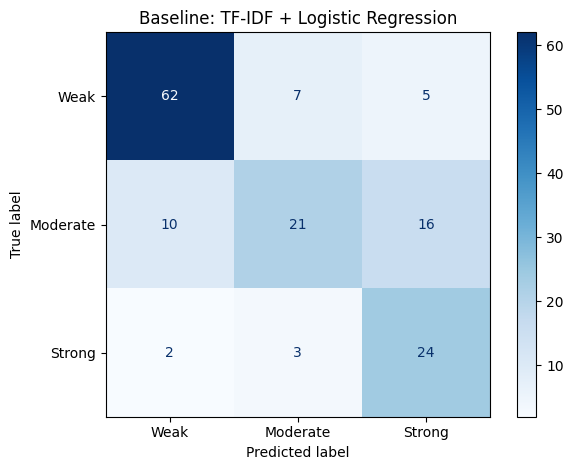

In [9]:

# STEP 6: Train a baseline text classifier

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

# Combine the resume and job description into one input
def combine_text(data):
    return (
        "Resume: " + data["resume_text"].astype(str)
        + " Job: " + data["job_text"].astype(str)
    )

X_train = combine_text(train_df)
X_val = combine_text(val_df)
X_test = combine_text(test_df)

y_train = train_df["label"].astype(str)
y_val = val_df["label"].astype(str)
y_test = test_df["label"].astype(str)

# TF-IDF converts text into numerical features.
# Logistic Regression learns to predict the three classes.
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        stop_words="english"
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train on the training split only
baseline.fit(X_train, y_train)

# Evaluate on the held-out test set
baseline_predictions = baseline.predict(X_test)

print("BASELINE TEST RESULTS")
print("Accuracy:", round(
    accuracy_score(y_test, baseline_predictions), 4
))

print("\nClassification report:")
print(classification_report(
    y_test,
    baseline_predictions,
    labels=["Weak", "Moderate", "Strong"],
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(
    y_test,
    baseline_predictions,
    labels=["Weak", "Moderate", "Strong"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Weak", "Moderate", "Strong"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Baseline: TF-IDF + Logistic Regression")
plt.tight_layout()
plt.savefig("baseline_confusion_matrix.png", dpi=150)
plt.show()


In [10]:

# STEP 7: Prepare DistilBERT for actual fine-tuning

import torch
import numpy as np
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from torch.utils.data import Dataset, DataLoader

MODEL_NAME = "distilbert-base-uncased"

# Use the same class-to-number mapping throughout the project
label2id = {"Weak": 0, "Moderate": 1, "Strong": 2}
id2label = {v: k for k, v in label2id.items()}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Prepare each resume-job pair as one input sequence
def prepare_records(data):
    records = []
    for _, row in data.iterrows():
        text = (
            "Resume: " + str(row["resume_text"])
            + " Job description: " + str(row["job_text"])
        )
        records.append({
            "text": text,
            "label": label2id[str(row["label"])]
        })
    return records

train_records = prepare_records(train_df)
val_records = prepare_records(val_df)
test_records = prepare_records(test_df)

class ResumeJobDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        item = self.records[index]
        encoded = tokenizer(
            item["text"],
            truncation=True,
            max_length=256,
            padding="max_length",
            return_tensors="pt"
        )
        return {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
            "labels": torch.tensor(item["label"], dtype=torch.long)
        }

train_dataset = ResumeJobDataset(train_records)
val_dataset = ResumeJobDataset(val_records)
test_dataset = ResumeJobDataset(test_records)

print("Model:", MODEL_NAME)
print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:", len(test_dataset))
print("GPU available:", torch.cuda.is_available())

# Load the pretrained model with a three-class classification head
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("Model ready for fine-tuning!")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Model: distilbert-base-uncased
Training examples: 700
Validation examples: 150
Test examples: 150
GPU available: True


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model ready for fine-tuning!


Training device: cuda

Starting experiment 1: learning rate = 2e-05


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


lr_2e-05 | Epoch 1/2 | Train loss: 1.0325 | Validation loss: 0.9703
lr_2e-05 | Epoch 2/2 | Train loss: 0.8481 | Validation loss: 0.8095


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Starting experiment 2: learning rate = 5e-05


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


lr_5e-05 | Epoch 1/2 | Train loss: 1.0427 | Validation loss: 1.0384
lr_5e-05 | Epoch 2/2 | Train loss: 0.9136 | Validation loss: 0.8102


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

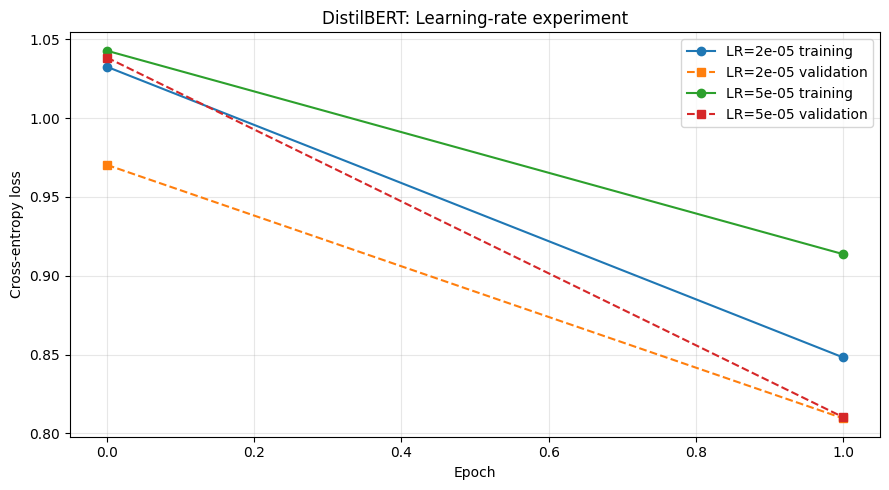


Best learning rate: 2e-05
Best model directory: model_lr_2e-05
Loss plot saved as loss_curves.png
Experiment histories saved.


In [11]:

# STEP 8: Fine-tune DistilBERT and compare two learning rates

import os
import gc
import copy
import json
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torch.optim import AdamW
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

# Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

BATCH_SIZE = 8
EPOCHS = 2
LEARNING_RATES = [2e-5, 5e-5]

def make_loader(data, shuffle=False):
    return DataLoader(
        data,
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )

train_loader = make_loader(train_dataset, shuffle=True)
val_loader = make_loader(val_dataset)

def evaluate_loss(model, loader):
    model.eval()
    total_loss = 0
    total_examples = 0

    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            n = batch["labels"].size(0)
            total_loss += outputs.loss.item() * n
            total_examples += n

    return total_loss / total_examples

def train_experiment(learning_rate, run_name):
    set_seed(42)

    # Start each experiment from the same pretrained checkpoint
    current_model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3,
        id2label=id2label,
        label2id=label2id
    ).to(device)

    optimizer = AdamW(
        current_model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    for epoch in range(EPOCHS):
        current_model.train()
        running_loss = 0
        examples_seen = 0

        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}

            optimizer.zero_grad()
            outputs = current_model(**batch)
            loss = outputs.loss
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                current_model.parameters(), 1.0
            )
            optimizer.step()

            n = batch["labels"].size(0)
            running_loss += loss.item() * n
            examples_seen += n

        train_loss = running_loss / examples_seen
        val_loss = evaluate_loss(current_model, val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(
            f"{run_name} | Epoch {epoch+1}/{EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Validation loss: {val_loss:.4f}"
        )

    # Save model and tokenizer for this experiment
    save_dir = f"model_{run_name}"
    current_model.save_pretrained(save_dir)
    tokenizer.save_pretrained(save_dir)

    result = {
        "learning_rate": learning_rate,
        "history": history,
        "model_dir": save_dir
    }

    del optimizer
    del current_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

experiments = []

for i, lr in enumerate(LEARNING_RATES, start=1):
    print(f"\nStarting experiment {i}: learning rate = {lr}")
    experiments.append(
        train_experiment(lr, f"lr_{lr}")
    )

# Plot training and validation loss for both experiments
plt.figure(figsize=(9, 5))

for exp in experiments:
    label = f"LR={exp['learning_rate']}"
    plt.plot(
        exp["history"]["train_loss"],
        marker="o",
        label=f"{label} training"
    )
    plt.plot(
        exp["history"]["val_loss"],
        marker="s",
        linestyle="--",
        label=f"{label} validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("DistilBERT: Learning-rate experiment")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("loss_curves.png", dpi=150)
plt.show()

# Select the experiment with the lowest final validation loss
best_exp = min(
    experiments,
    key=lambda exp: exp["history"]["val_loss"][-1]
)

best_model_dir = best_exp["model_dir"]

print("\nBest learning rate:", best_exp["learning_rate"])
print("Best model directory:", best_model_dir)
print("Loss plot saved as loss_curves.png")

with open("experiment_results.json", "w") as f:
    json.dump(experiments, f, indent=2)

print("Experiment histories saved.")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

FINE-TUNED MODEL: TEST RESULTS
Selected learning rate: 2e-05
Test accuracy: 0.64

Classification report:
              precision    recall  f1-score   support

        Weak       0.76      0.70      0.73        74
    Moderate       0.50      0.47      0.48        47
      Strong       0.58      0.76      0.66        29

    accuracy                           0.64       150
   macro avg       0.61      0.64      0.62       150
weighted avg       0.65      0.64      0.64       150


BASELINE VS FINE-TUNED MODEL
Baseline accuracy: 0.7133
Fine-tuned accuracy: 0.6400
Baseline macro F1: 0.6750
Fine-tuned macro F1: 0.6242


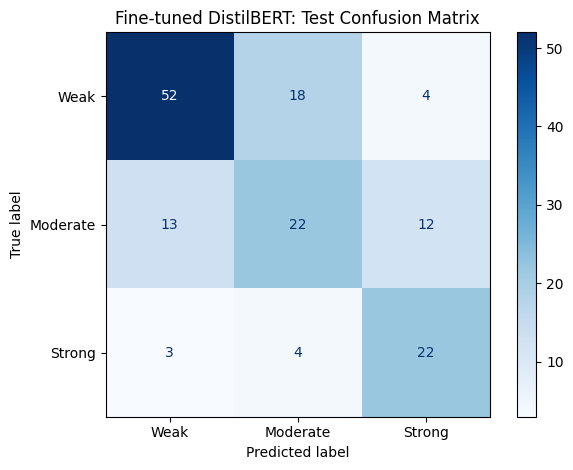


Saved final_metrics.json
Saved test_predictions.csv
Saved finetuned_confusion_matrix.png


In [12]:

# STEP 9: Final test-set evaluation

import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from transformers import AutoModelForSequenceClassification
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the model selected using validation loss
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

best_model = AutoModelForSequenceClassification.from_pretrained(
    best_model_dir
).to(device)

best_model.eval()

test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

all_predictions = []
all_probabilities = []
all_true_labels = []

with torch.no_grad():
    for batch in test_loader:
        labels = batch["labels"].cpu().numpy()
        inputs = {
            key: value.to(device)
            for key, value in batch.items()
            if key != "labels"
        }

        outputs = best_model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=-1)
        predictions = probabilities.argmax(dim=-1)

        all_true_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())
        all_probabilities.extend(probabilities.cpu().numpy().tolist())

class_names = ["Weak", "Moderate", "Strong"]

print("FINE-TUNED MODEL: TEST RESULTS")
print("Selected learning rate:", best_exp["learning_rate"])
print("Test accuracy:", round(
    accuracy_score(all_true_labels, all_predictions), 4
))

print("\nClassification report:")
print(classification_report(
    all_true_labels,
    all_predictions,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

# Calculate summary metrics
precision, recall, macro_f1, _ = precision_recall_fscore_support(
    all_true_labels,
    all_predictions,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

results = {
    "model": "DistilBERT fine-tuned",
    "selected_learning_rate": best_exp["learning_rate"],
    "test_accuracy": accuracy_score(all_true_labels, all_predictions),
    "macro_precision": precision,
    "macro_recall": recall,
    "macro_f1": macro_f1
}

# Compare against the baseline already evaluated on the same test split
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
_, _, baseline_macro_f1, _ = precision_recall_fscore_support(
    y_test,
    baseline_predictions,
    labels=["Weak", "Moderate", "Strong"],
    average="macro",
    zero_division=0
)

print("\nBASELINE VS FINE-TUNED MODEL")
print(f"Baseline accuracy: {baseline_accuracy:.4f}")
print(f"Fine-tuned accuracy: {results['test_accuracy']:.4f}")
print(f"Baseline macro F1: {baseline_macro_f1:.4f}")
print(f"Fine-tuned macro F1: {macro_f1:.4f}")

# Plot and save the final confusion matrix
cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Fine-tuned DistilBERT: Test Confusion Matrix")
plt.tight_layout()
plt.savefig("finetuned_confusion_matrix.png", dpi=150)
plt.show()


# Save predictions without exposing resume or job-description text
test_results = pd.DataFrame({
    "true_label": [id2label[int(x)] for x in all_true_labels],
    "predicted_label": [id2label[int(x)] for x in all_predictions]
})

for i, name in enumerate(class_names):
    test_results[f"probability_{name.lower()}"] = [
        float(p[i]) for p in all_probabilities
    ]

test_results.to_csv("test_predictions.csv", index=False)

with open("final_metrics.json", "w") as f:
    json.dump(results, f, indent=2)

print("\nSaved final_metrics.json")
print("Saved test_predictions.csv")
print("Saved finetuned_confusion_matrix.png")


Class weights (Weak, Moderate, Strong): [0.6763285  1.07033639 1.70316302]


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2 | Weighted train loss: 1.0964 | Validation loss: 1.0115
Epoch 2/2 | Weighted train loss: 0.9016 | Validation loss: 0.8104


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

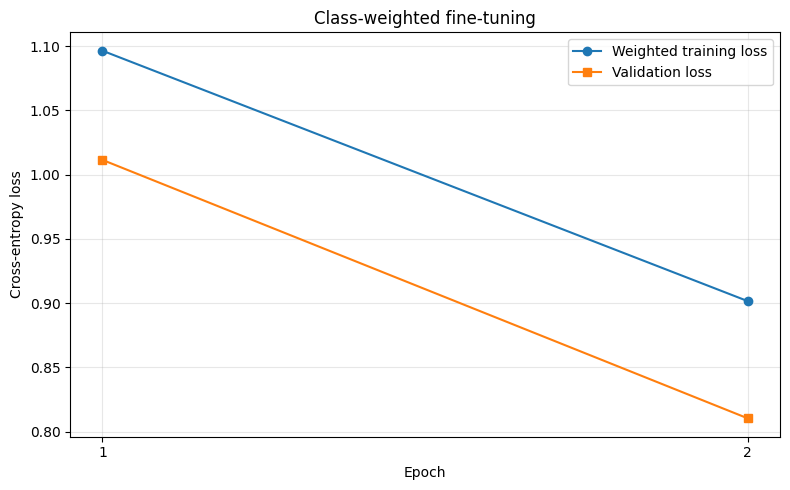

Best validation loss: 0.8104
Saved checkpoint: model_weighted


In [13]:

# STEP 10: Try class-weighted cross-entropy loss

import os
import gc
import copy
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from transformers import AutoModelForSequenceClassification
from torch.optim import AdamW
from sklearn.utils.class_weight import compute_class_weight

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(42)

# Give less frequent classes more weight during training
train_labels = train_df["label"].astype(str).map(label2id).to_numpy()

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=train_labels
)

class_weights = torch.tensor(
    weights, dtype=torch.float32, device=device
)

print("Class weights (Weak, Moderate, Strong):", weights)

# Start again from the original pretrained model
improved_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
).to(device)

optimizer = AdamW(improved_model.parameters(), lr=2e-5)

best_val_loss = float("inf")
best_state = None
history_weighted = {"train_loss": [], "val_loss": []}
epochs = 2

for epoch in range(epochs):
    improved_model.train()
    total_train_loss = 0.0
    total_train_examples = 0

    for batch in train_loader:
        batch = {k: v.to(device) for k, v in batch.items()}

        optimizer.zero_grad()

        # Compute weighted cross-entropy explicitly
        outputs = improved_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        loss = F.cross_entropy(
            outputs.logits,
            batch["labels"],
            weight=class_weights
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            improved_model.parameters(), 1.0
        )
        optimizer.step()

        n = batch["labels"].size(0)
        total_train_loss += loss.item() * n
        total_train_examples += n

    train_loss = total_train_loss / total_train_examples

    # Use ordinary, unweighted validation loss for checkpoint selection
    improved_model.eval()
    val_total = 0.0
    val_examples = 0

    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}

            outputs = improved_model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )

            val_loss = F.cross_entropy(
                outputs.logits, batch["labels"]
            )

            n = batch["labels"].size(0)
            val_total += val_loss.item() * n
            val_examples += n

    val_loss = val_total / val_examples

    history_weighted["train_loss"].append(train_loss)
    history_weighted["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Weighted train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in improved_model.state_dict().items()
        }

# Save the best validation checkpoint
improved_model.load_state_dict(best_state)
improved_model.save_pretrained("model_weighted")
tokenizer.save_pretrained("model_weighted")

plt.figure(figsize=(8, 5))
plt.plot(history_weighted["train_loss"], marker="o",
         label="Weighted training loss")
plt.plot(history_weighted["val_loss"], marker="s",
         label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Class-weighted fine-tuning")
plt.xticks(range(epochs), range(1, epochs + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("weighted_loss_curves.png", dpi=150)
plt.show()

print("Best validation loss:", round(best_val_loss, 4))
print("Saved checkpoint: model_weighted")

del optimizer
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


In [14]:

# STEP 11: Evaluate the class-weighted model

import torch
import numpy as np
import pandas as pd
from transformers import AutoModelForSequenceClassification
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weighted_model = AutoModelForSequenceClassification.from_pretrained(
    "model_weighted"
).to(device)

weighted_model.eval()

weighted_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False
)

weighted_true = []
weighted_pred = []

with torch.no_grad():
    for batch in weighted_loader:
        labels = batch["labels"].cpu().numpy()
        inputs = {
            k: v.to(device)
            for k, v in batch.items()
            if k != "labels"
        }

        logits = weighted_model(**inputs).logits
        predictions = logits.argmax(dim=-1).cpu().numpy()

        weighted_true.extend(labels.tolist())
        weighted_pred.extend(predictions.tolist())

weighted_accuracy = accuracy_score(weighted_true, weighted_pred)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        weighted_true,
        weighted_pred,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )
)

print("CLASS-WEIGHTED MODEL: TEST RESULTS")
print("Accuracy:", round(weighted_accuracy, 4))
print("Macro precision:", round(weighted_precision, 4))
print("Macro recall:", round(weighted_recall, 4))
print("Macro F1:", round(weighted_f1, 4))

print("\nClassification report:")
print(classification_report(
    weighted_true,
    weighted_pred,
    labels=[0, 1, 2],
    target_names=["Weak", "Moderate", "Strong"],
    zero_division=0
))


# Summary using results from the current 1,000-example experiment
comparison = pd.DataFrame([
    {
        "Model": "TF-IDF baseline",
        "Accuracy": 0.7133,
        "Macro F1": 0.6750
    },
    {
        "Model": "DistilBERT, LR 2e-5",
        "Accuracy": 0.6400,
        "Macro F1": 0.6242
    },
    {
        "Model": "Class-weighted DistilBERT",
        "Accuracy": weighted_accuracy,
        "Macro F1": weighted_f1
    }
])

print("\nMODEL COMPARISON")
display(comparison.round(4))

comparison.to_csv("model_comparison.csv", index=False)
print("Saved model_comparison.csv")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

CLASS-WEIGHTED MODEL: TEST RESULTS
Accuracy: 0.6467
Macro precision: 0.6261
Macro recall: 0.6476
Macro F1: 0.6343

Classification report:
              precision    recall  f1-score   support

        Weak       0.73      0.72      0.72        74
    Moderate       0.52      0.47      0.49        47
      Strong       0.63      0.76      0.69        29

    accuracy                           0.65       150
   macro avg       0.63      0.65      0.63       150
weighted avg       0.64      0.65      0.64       150


MODEL COMPARISON


,Model,Accuracy,Macro F1
0,TF-IDF baseline,0.7133,0.6750
1,"DistilBERT, LR 2e-5",0.6400,0.6242
2,Class-weighted DistilBERT,0.6467,0.6343


Saved model_comparison.csv


In [15]:

# STEP 12: Test three new resume-job pairs

import pandas as pd
import torch
import re

# Three new, illustrative examples for our demo
demo_examples = [
    {
        "name": "Example 1 - Strong candidate",
        "resume": (
            "Data analyst with experience in Python, SQL, Excel, "
            "Power BI, Tableau, statistics, pandas and data visualization."
        ),
        "job": (
            "Data Analyst required. Skills: Python, SQL, Excel, "
            "Power BI, Tableau, statistics, pandas and data visualization."
        )
    },
    {
        "name": "Example 2 - Partial match",
        "resume": (
            "Junior data analyst with knowledge of Python, SQL and Excel. "
            "Completed small data analysis projects."
        ),
        "job": (
            "Data Analyst required. Skills: Python, SQL, Excel, "
            "Power BI, Tableau, statistics, pandas and data visualization."
        )
    },
    {
        "name": "Example 3 - Weak candidate",
        "resume": (
            "Customer service assistant experienced in communication, "
            "teamwork and customer support."
        ),
        "job": (
            "Data Analyst required. Skills: Python, SQL, Excel, "
            "Power BI, Tableau, statistics, pandas and data visualization."
        )
    }
]

skill_list = [
    "Python", "SQL", "Excel", "Power BI", "Tableau",
    "statistics", "data visualization", "pandas",
    "HTML", "CSS", "JavaScript", "React", "Node.js",
    "Git", "REST APIs", "machine learning", "PyTorch",
    "scikit-learn", "data preprocessing", "model evaluation",
    "SEO", "content marketing", "Google Analytics",
    "social media", "copywriting", "campaign analysis",
    "communication", "teamwork", "problem solving"
]

def extract_skills(text):
    found = []
    for skill in skill_list:
        pattern = r"(?<!\w)" + re.escape(skill) + r"(?!\w)"
        if re.search(pattern, text, flags=re.IGNORECASE):
            found.append(skill)
    return found

device = next(best_model.parameters()).device
demo_results = []

for example in demo_examples:
    combined = (
        "Resume: " + example["resume"]
        + " Job description: " + example["job"]
    )

    # Baseline prediction and probabilities
    baseline_class = baseline.predict([combined])[0]
    baseline_probs = baseline.predict_proba([combined])[0]
    baseline_confidence = float(max(baseline_probs))

    # Fine-tuned DistilBERT prediction and probabilities
    encoded = tokenizer(
        combined,
        truncation=True,
        max_length=256,
        padding="max_length",
        return_tensors="pt"
    )
    encoded = {k: v.to(device) for k, v in encoded.items()}

    best_model.eval()
    with torch.no_grad():
        logits = best_model(**encoded).logits
        probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()

    bert_class = id2label[int(probs.argmax())]

    # Transparent keyword comparison, separate from model prediction
    resume_skills = extract_skills(example["resume"])
    job_skills = extract_skills(example["job"])
    matched = [s for s in job_skills if s in resume_skills]
    missing = [s for s in job_skills if s not in resume_skills]

    demo_results.append({
        "Example": example["name"],
        "Baseline prediction": baseline_class,
        "Baseline confidence": round(baseline_confidence, 3),
        "DistilBERT prediction": bert_class,
        "DistilBERT confidence": round(float(probs.max()), 3),
        "Matched skills": ", ".join(matched) or "None detected",
        "Missing skills": ", ".join(missing) or "None detected"
    })

demo_df = pd.DataFrame(demo_results)
display(demo_df)

demo_df.to_csv("three_demo_examples.csv", index=False)
print("Saved three_demo_examples.csv")


,Example,Baseline prediction,Baseline confidence,DistilBERT prediction,DistilBERT confidence,Matched skills,Missing skills
0,Example 1 - Strong candidate,Weak,0.420,Weak,0.522,"Python, SQL, Excel, Power BI, Tableau, statist...",None detected
1,Example 2 - Partial match,Moderate,0.420,Weak,0.522,"Python, SQL, Excel","Power BI, Tableau, statistics, data visualizat..."
2,Example 3 - Weak candidate,Weak,0.461,Weak,0.536,None detected,"Python, SQL, Excel, Power BI, Tableau, statist..."


Saved three_demo_examples.csv


In [16]:

!pip -q install gradio


In [17]:

!pip -q install pypdf python-docx


In [18]:

import os
from pypdf import PdfReader
from docx import Document

def extract_resume_text(file_path):
    if not file_path:
        return ""

    ext = os.path.splitext(file_path)[1].lower()

    if ext == ".pdf":
        reader = PdfReader(file_path)
        text = "\n".join(
            page.extract_text() or ""
            for page in reader.pages
        )
    elif ext == ".docx":
        doc = Document(file_path)
        text = "\n".join(p.text for p in doc.paragraphs)
    else:
        raise ValueError("Please upload a PDF or DOCX file.")

    if not text.strip():
        raise ValueError(
            "No readable text found. Try a text-based PDF or DOCX."
        )

    return text


In [ ]:

# FINAL DEMO: PDF/DOCX upload + pasted text + model comparison

import re
import torch
import gradio as gr

SKILLS = [
    "Python", "SQL", "Excel", "Power BI", "Tableau",
    "statistics", "data visualization", "pandas",
    "HTML", "CSS", "JavaScript", "React", "Node.js",
    "Git", "REST APIs", "machine learning", "PyTorch",
    "scikit-learn", "data preprocessing", "model evaluation",
    "SEO", "content marketing", "Google Analytics",
    "social media", "copywriting", "campaign analysis",
    "communication", "teamwork", "problem solving"
]

def get_skills(text):
    return [
        skill for skill in SKILLS
        if re.search(
            r"(?<!\w)" + re.escape(skill) + r"(?!\w)",
            text,
            flags=re.IGNORECASE
        )
    ]

def final_demo(resume_file, resume_text, job):
    # Use the uploaded document if supplied; otherwise use pasted text.
    if resume_file:
        resume = extract_resume_text(resume_file)
    else:
        resume = resume_text or ""

    if not resume.strip() or not (job or "").strip():
        raise gr.Error(
            "Upload a resume or paste its text, and enter a job description."
        )

    combined = "Resume: " + resume + " Job: " + job

    # TF-IDF baseline
    baseline_class = baseline.predict([combined])[0]
    baseline_probs = baseline.predict_proba([combined])[0]

    baseline_scores = {
        str(name): float(baseline_probs[i])
        for i, name in enumerate(baseline.classes_)
    }

    # Fine-tuned DistilBERT
    device = next(best_model.parameters()).device
    encoded = tokenizer(
        combined,
        truncation=True,
        max_length=256,
        padding="max_length",
        return_tensors="pt"
    )
    encoded = {k: v.to(device) for k, v in encoded.items()}

    best_model.eval()
    with torch.no_grad():
        logits = best_model(**encoded).logits
        probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()

    bert_class = id2label[int(probs.argmax())]

    # Transparent keyword-based skill comparison
    resume_skills = get_skills(resume)
    job_skills = get_skills(job)
    matched = [s for s in job_skills if s in resume_skills]
    missing = [s for s in job_skills if s not in resume_skills]

    comparison = (
        f"TF-IDF baseline prediction: {baseline_class}\n"
        f"DistilBERT prediction: {bert_class}\n\n"
        "Experimental predictions only; not hiring decisions."
    )

    bert_scores = "\n".join(
        f"{id2label[i]}: {float(probs[i]):.3f}"
        for i in range(len(probs))
    )

    return (
        comparison,
        baseline_scores,
        ", ".join(matched) or "None detected",
        ", ".join(missing) or "None detected",
        bert_scores
    )

final_app = gr.Interface(
    fn=final_demo,
    inputs=[
        gr.File(
            label="Upload Resume (PDF or DOCX)",
            file_types=[".pdf", ".docx"],
            type="filepath"
        ),
        gr.Textbox(
            label="Or Paste Resume Text",
            lines=5,
            placeholder="Optional if you upload a file..."
        ),
        gr.Textbox(
            label="Job Description",
            lines=7,
            placeholder="Paste job requirements..."
        )
    ],
    outputs=[
        gr.Textbox(label="Model Comparison"),
        gr.Label(label="TF-IDF Baseline Class Scores"),
        gr.Textbox(label="Matched Skills"),
        gr.Textbox(label="Missing Skills"),
        gr.Textbox(label="DistilBERT Class Scores")
    ],
    title="Resume–Job Match Analyzer",
    description=(
        "Upload a text-based PDF or DOCX resume, or paste resume text. "
        "Compare the TF-IDF baseline with fine-tuned DistilBERT."
    )
)

final_app.launch(share=True)
